# E69: Does RL on Qwen3-1.7B gain more than the same loop with shuffled rewards?

**The answer.** Under the strict grader, RL beat this shuffled-reward run by three to eight points on the same test problems, depending on how long answers are counted. On answers all three states finish it reads +3.2 and +3.1. The standard error over problems, with the weights fixed, is near one point. Each arm is one seed, so the spread between runs is not measured, for either arm. With format ignored, on those same answers, the lead is about one point, +1.2 and +0.7, and not separable from zero. Accepting forms like "So the answer is 20" takes the strict lead there to +1.25 (0.90) and +0.81 (1.06). So the firm lead may be largely answer format, and better maths is not shown. The null's own gain is also one seed's and remains unexplained.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_rl")
FIG = ROOT / "figures"
A = json.loads((ROOT / "results/lr1e-6w10/analysis.json").read_text())


def show(name):
    display(Image(filename=str(FIG / name), width=820))


def cell(x):
    return f"{x['mean']:+.1f} ({x['se']:.1f})"


def gains_table(grader):
    head = "| set | arm | drop rule | whole answers | capped answers |\n|---|---|---|---|---|\n"
    names = {"R": "RL", "N": "null", "F": "own-samples SFT", "R-N": "RL minus null"}
    body = ""
    for s, label in (("gsm8k", "GSM8K test"), ("gsm1k", "GSM1K")):
        for a, n in names.items():
            g = A[s]["gains"][grader][a]
            body += f"| {label} | {n} | {cell(g['drop'])} | {cell(g['whole'])} | {cell(g['capped'])} |\n"
    display(Markdown(head + body))


## What we were trying to test

The project needs a real post-training update to carry through a decomposition, and no reinforcement-learning update of Qwen3-1.7B existed. So we trained the unchanged model, with thinking off, on GSM8K train problems for one hundred steps, three ways.

- **RL.** Each step draws 64 new problems and 8 samples per problem at temperature 1. A right answer that ends inside the 512-token window earns reward 1, anything else 0. Each sample's log-probability is pushed by its reward minus its problem's mean reward. This is GRPO in the Dr. GRPO form, with one update per batch.
- **The shuffled-reward null.** The same loop, sampling from its own changing weights, with the rewards shuffled among each problem's samples. It rules out that any update of this size and kind moves accuracy by itself.
- **Own-samples SFT.** Supervised training on the correct samples of the unchanged model, on the same prompts and optimiser. Its samples are drawn once from the unchanged model and never redrawn.

All three use AdamW at a rate of one in a million, reached over ten warm-up steps. Accuracy is the greedy answer, graded strictly. The response must end with the line "The answer is N." It is read on GSM8K test, 1,319 problems not trained on. It is also read on GSM1K, 1,197 new problems written in GSM8K's style.

Long answers need a rule, and the code has three. The **drop rule**, which we filed, compares only problems whose answers fit the window both before and after. **Whole answers** grades everything, up to 512 new tokens. **Capped answers** grades everything at the point where the window cuts it. The window is what the reward and the decomposition see.


## What we expected, and why

We expected RL to gain three to eight points on test. We expected about the same on GSM1K, since the gain should be skill rather than memory. We expected the null to stay within a point and a half, because its expected gradient is zero. One update per batch also removes the clipping that the Spurious Rewards paper blames for gains under random rewards. We expected a right-over-wrong signal to grow in RL and stay near zero in the null. We did not know whether SFT would move the policy more than RL.


## Did RL gain more than the null on the same problems?


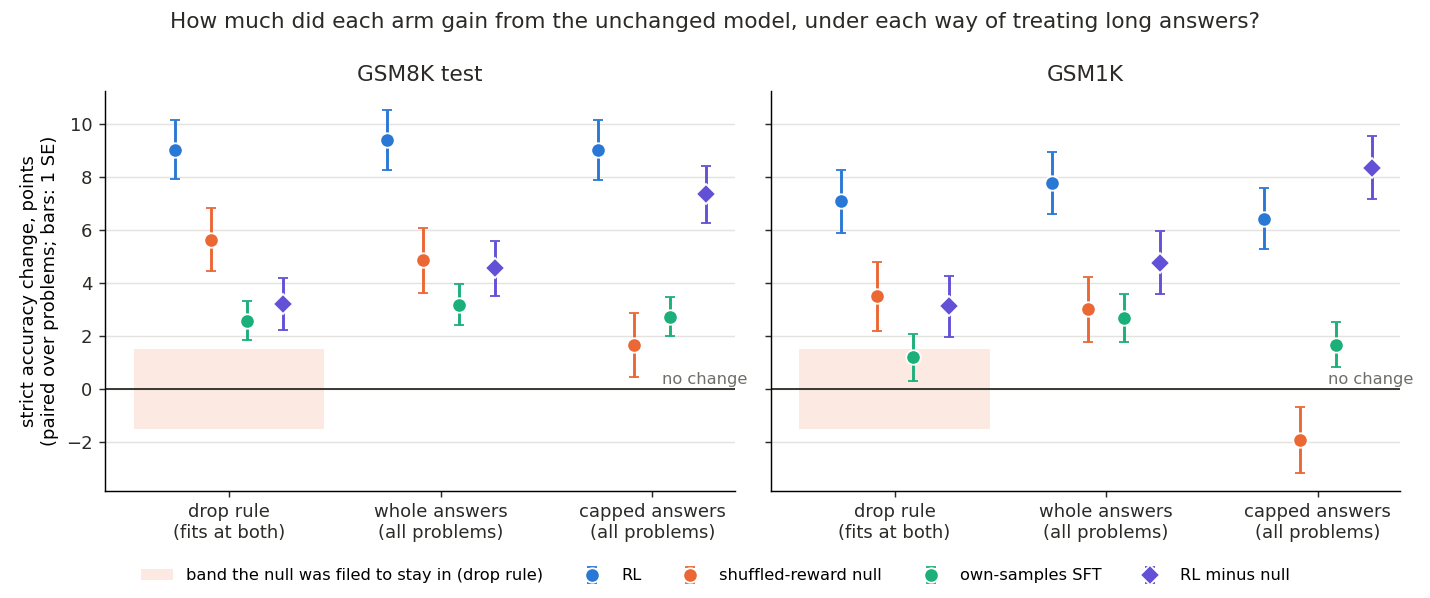

| set | arm | drop rule | whole answers | capped answers |
|---|---|---|---|---|
| GSM8K test | RL | +9.0 (1.1) | +9.4 (1.1) | +9.0 (1.1) |
| GSM8K test | null | +5.6 (1.2) | +4.9 (1.2) | +1.7 (1.2) |
| GSM8K test | own-samples SFT | +2.6 (0.7) | +3.2 (0.8) | +2.7 (0.7) |
| GSM8K test | RL minus null | +3.2 (1.0) | +4.5 (1.0) | +7.4 (1.1) |
| GSM1K | RL | +7.1 (1.2) | +7.8 (1.2) | +6.4 (1.2) |
| GSM1K | null | +3.5 (1.3) | +3.0 (1.2) | -1.9 (1.2) |
| GSM1K | own-samples SFT | +1.2 (0.9) | +2.7 (0.9) | +1.7 (0.8) |
| GSM1K | RL minus null | +3.1 (1.2) | +4.8 (1.2) | +8.4 (1.2) |


In [2]:
show("gains.png")
gains_table("strict")


**Reading it.** Yes under the strict grader, for all three rules and on both sets, and the lead depends on the rule. The violet diamonds are RL minus the null on the same problems. They read about three points under the drop rule, under five on whole answers, and seven or eight on capped answers. RL itself barely depends on the rule, while the null falls from a clear gain to nothing as long answers count against it. These standard errors count problems at fixed weights. They carry no spread between runs of either arm, so read the lead as being over this one null run. The two test sets read the same two sets of weights, so their agreement does not replicate the difference between the arms.


## Does RL's lead survive a grader that ignores the format?


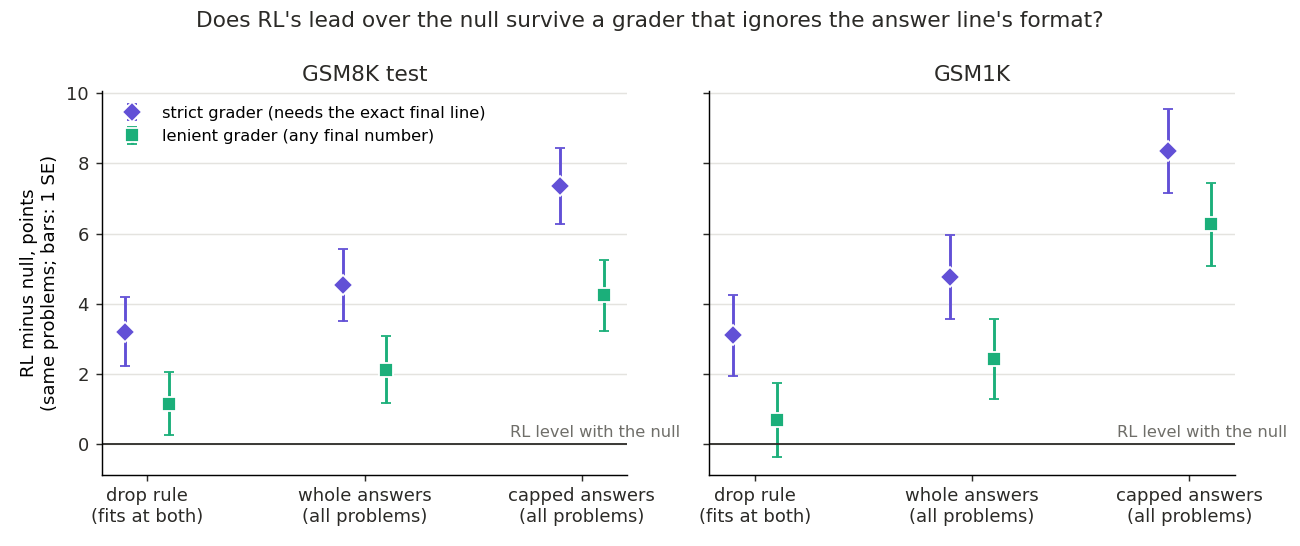

| set | arm | drop rule | whole answers | capped answers |
|---|---|---|---|---|
| GSM8K test | RL | +6.7 (1.1) | +6.3 (1.1) | +6.8 (1.1) |
| GSM8K test | null | +5.4 (1.1) | +4.2 (1.1) | +2.6 (1.1) |
| GSM8K test | own-samples SFT | +0.6 (0.6) | +0.5 (0.6) | +0.5 (0.6) |
| GSM8K test | RL minus null | +1.2 (0.9) | +2.1 (1.0) | +4.2 (1.0) |
| GSM1K | RL | +5.6 (1.1) | +6.0 (1.1) | +5.7 (1.1) |
| GSM1K | null | +4.6 (1.2) | +3.6 (1.1) | -0.6 (1.2) |
| GSM1K | own-samples SFT | +0.0 (0.8) | +0.8 (0.9) | +0.4 (0.8) |
| GSM1K | RL minus null | +0.7 (1.1) | +2.4 (1.1) | +6.3 (1.2) |


In [3]:
show("grader.png")
gains_table("lenient")


**Reading it.** Only in part. The lenient grader accepts any final number, so it removes what RL gained by writing the requested answer line. No answer of RL's that fits the window is right yet missing that line. On answers all three states finish, RL's lead falls to about one point, within its error on both sets. With answers allowed to run long it is about two. It reads four to six on capped answers, where an answer past the window counts as wrong, and most of that is the null's answers not finishing. A narrower change says the same. Keeping the strict grader but accepting forms like "So the answer is 20", the lead on answers all three states finish reads +1.25 and +0.81, which this figure does not plot. So the firm lead may be largely the reward's format. Own-samples SFT gained almost nothing under the lenient grader, so its gain is format too.


## Does the sampled policy agree with greedy accuracy?


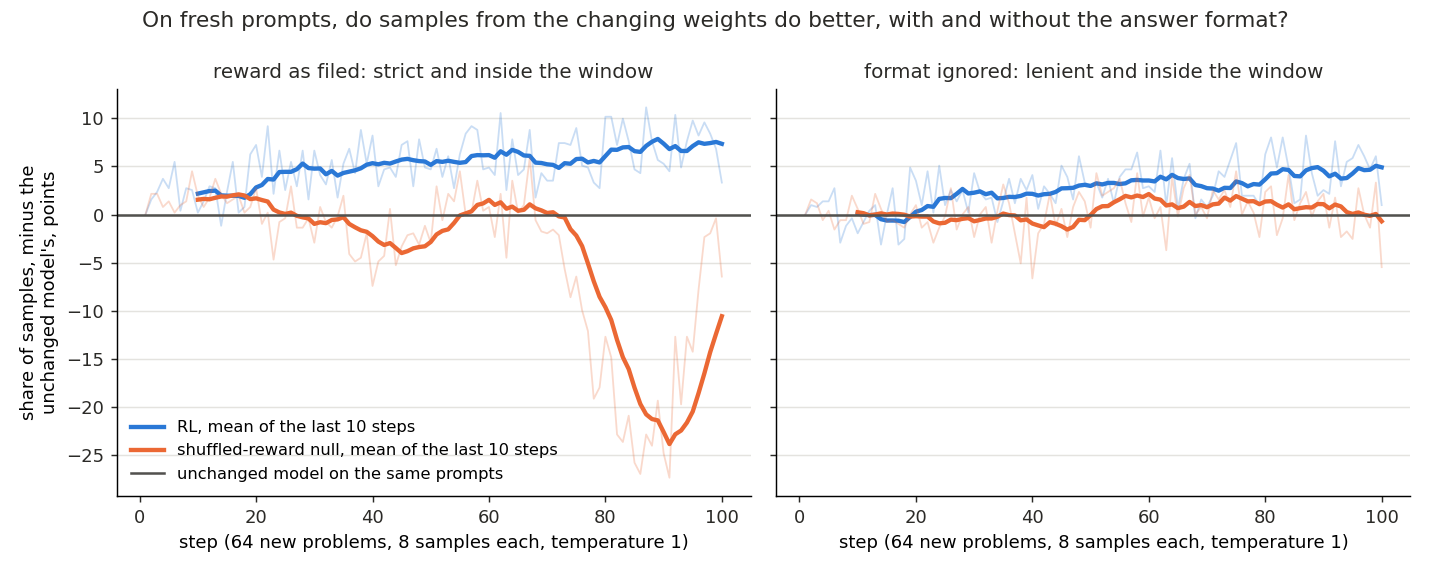

In [4]:
show("reward.png")


**Reading it.** RL does, and the null does not. The zero line is the unchanged model's reward on the same prompts and seeds. On the left, RL climbs to about seven points above it, while the null drifts, then collapses by about twenty points between steps 76 and 95, and largely recovers. On the right, format is ignored and an answer past the window counts as wrong. RL climbs to five points, with a standard error of about one, and the null stays within two points of zero throughout. RL's lead over the null reads +5 in the last five steps and +3 averaged over the last fifty. Among finished samples the null's right-number share rises as much as RL's, and its lower finishing share cancels that. That right panel is the steadiest evidence we have, since the same one hundred steps give the null's noise floor directly.


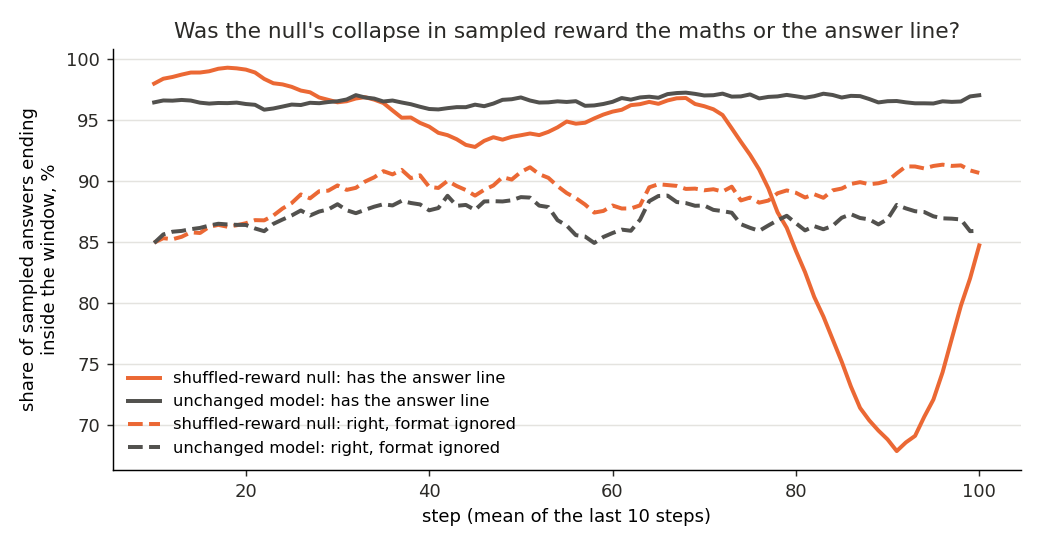

In [5]:
show("collapse.png")


**Reading it.** The null's collapse is the answer line, not the maths. Solid lines show the share of finished samples that write the requested answer line: the null's drops from about 96 to under 70 percent and comes back. Dashed lines show the share of finished samples right under the lenient grader, and the null's stays at or above the unchanged model's. Finished answers are selected, and the null finishes fewer, so this does not show its maths improved.


## What is the null's gain made of?


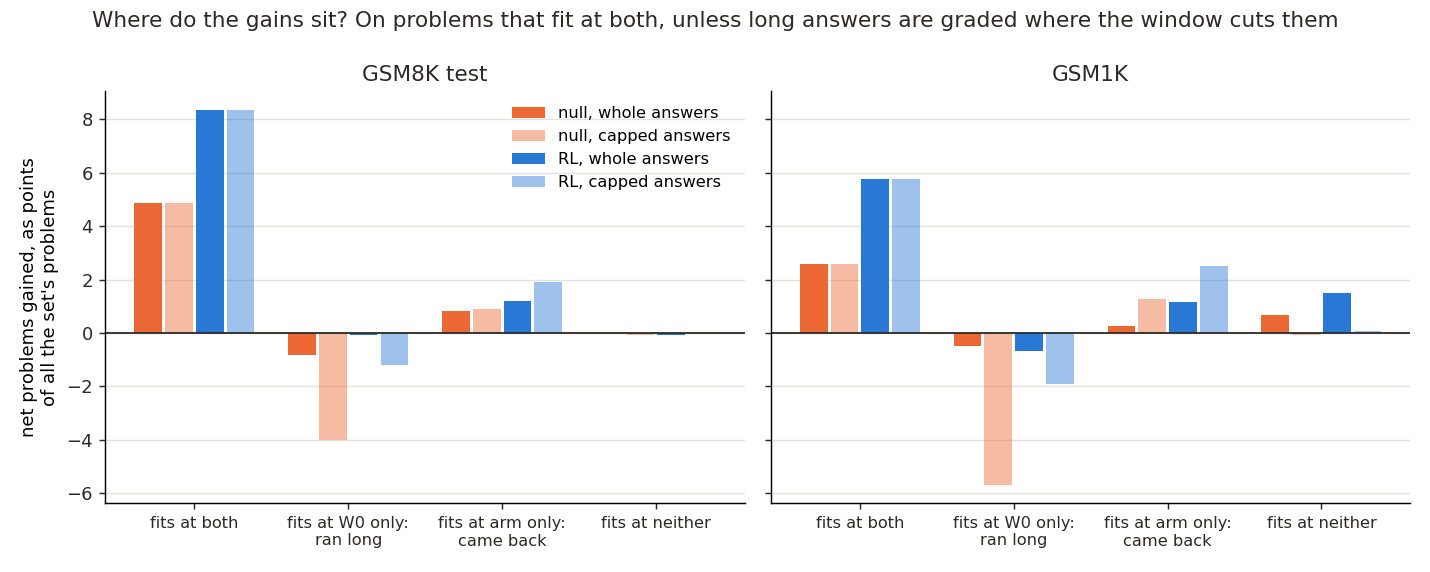

In [6]:
show("accounting.png")


**Reading it.** The filed gain is answers that changed on problems kept at both states. On GSM8K test, 125 kept problems went from wrong to right and 61 from right to wrong, a net of 64. On whole answers the rest nets to zero, so that gain is the same 64 problems. With an answer past the window counted as wrong it nearly vanishes, because 53 problems the unchanged model got right now run past the cut. Twenty-three of those 53 are right if allowed to finish. So the drop rule reads a gain that the window takes back, and on GSM1K the null ends below zero.


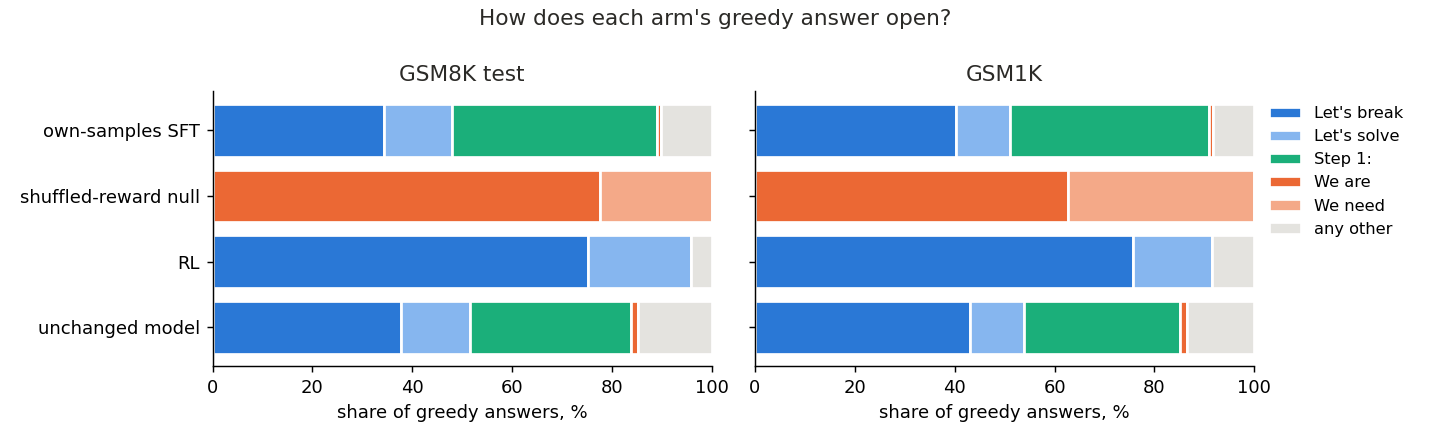

In [7]:
show("openings.png")


**Reading it.** Every greedy answer of the null now opens "We are" or "We need", against under two percent at the unchanged model. Sampled answers flip too, mostly by step 50. RL moved differently, dropping "Step 1:" for "Let's". This was our favoured explanation, and its most direct test counts against it. Among the unchanged model's own samples on the same problem, answers opening "We" are slightly worse than those opening "Let", not better. Answers opening "Step" and "Let" read the same, so the large differences between openings are which problems each goes with. That test reads samples of the unchanged model, not greedy answers of the null, so forcing the opening is still worth doing.


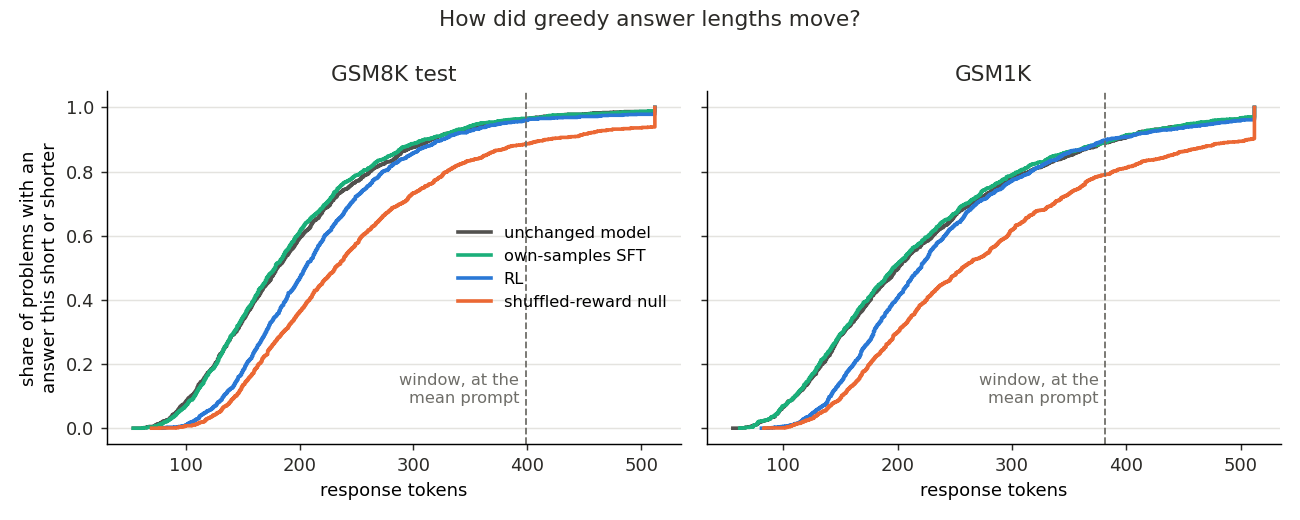

In [8]:
show("lengths.png")


**Reading it.** The null's greedy answers grew by about a quarter, RL's by about a tenth, and SFT's not at all. The null's growth is what pushes problems past the window. Length does not explain the gain problem by problem. Among kept problems, those that went wrong to right lengthened as much as those that went right to wrong. That test is blind to a uniform change of style. Answers with an explicit self-check became far more common in the null, but they do not carry the gain either.


## Does the policy move as the weights move?


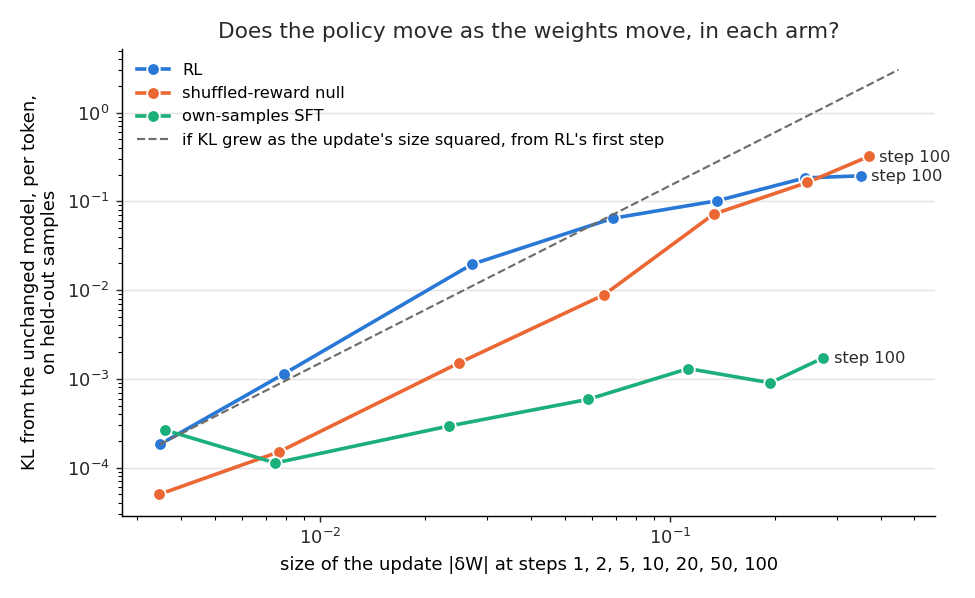

In [9]:
show("kl.png")


**Reading it.** In the null it does, and in own-samples SFT it hardly does. The null runs parallel to the dashed slope, so its divergence from the unchanged model stays proportional to the update's size squared. SFT starts near that line, then falls about a thousandfold below it, and twice its divergence fell while its weights moved further. The update's size at step 100 is still three quarters of the null's. This is what a pull toward the unchanged model would look like, since SFT's samples never leave it. It does not prove that. SFT's weights keep their direction as the others' do, so any such pull acts on the output and not on the weights as a whole. SFT also has no baseline, and RL flattens too. Only an arm that changes one of those things can separate them.


## Does the right-over-wrong signal separate RL from the null?


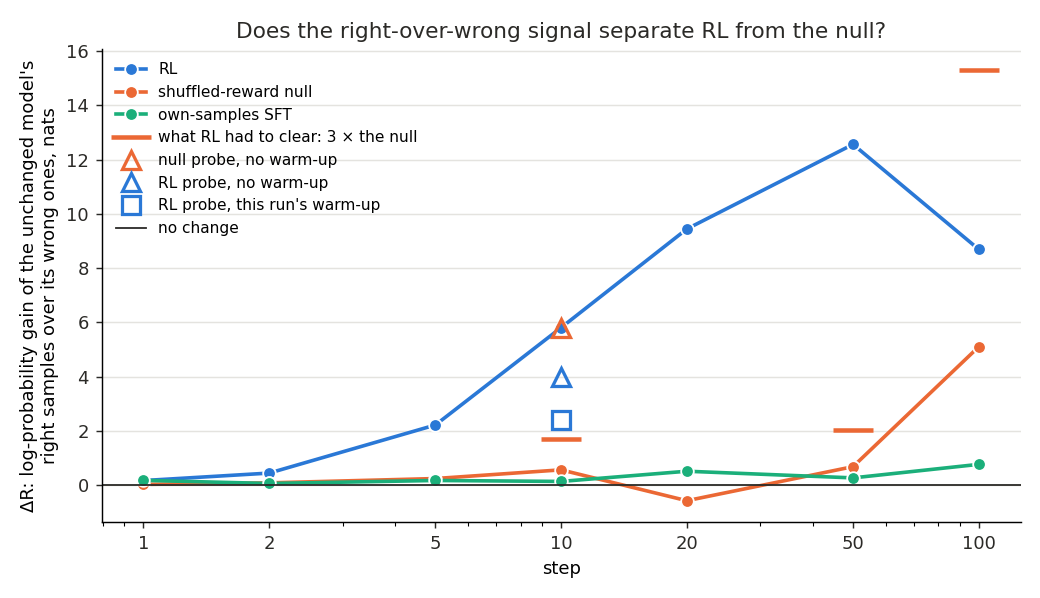

In [10]:
show("delta_r.png")


**Reading it.** Up to step 50 yes, at step 100 no. This signal measures how much more the update favours the unchanged model's right samples over its wrong ones on held-out problems. RL leads by a wide margin until step 50, then drops as the null jumps, so the filed threefold margin fails at the last step. The null's own readings wander around zero and then jump, so this signal has a noise floor of several nats that we did not expect. The orange triangle is the earlier probe of the null without warm-up, about ten times this run's reading at step 10. That probe's path and readout problems both differ, and its standard error was not saved, so the gap is only partly explained.


## What we learned

Under the strict grader, RL's update raised accuracy on fresh problems more than a shuffled-reward run did, sampled and greedy. Part of that lead is the reward's answer format, and on answers all three states finish that part may be most of it. With format ignored and an answer past the window counted as wrong, four to six points of greedy lead remain, most of them because the null's answers more often fail to finish. On answers all three states finish, about one point remains, within noise, so better maths is not shown. The update is still ready to go forward to the decomposition, with that reading attached. The null cannot be read as an update that changes no behaviour. It moves the policy further than RL, rewrites how every greedy answer opens, and can lose the answer line for twenty steps. The updates' weight changes are almost orthogonal, and direction alone does not tell them apart. Greedy strict accuracy at one step is a poor measure of what an update did here, and the format-ignored share of samples inside the window is a much steadier one.

## How compelling is the evidence

There is one seed per arm, and one accuracy reading, at step 100. Standard errors are over problems and hold the weights fixed, so the spread between runs is not measured, for either arm. The sampled lead moves between about zero and about six points in five-step bins, so step 100 is one point on a moving curve. Sampled readings are on training-pool problems, each new when drawn, with standard errors over steps. The lenient grader takes the last number, so it is a coarse stand-in for correct maths. Accuracy is blind to anything between the saved states. In the scorecard, "learns" is the filed label for a gain that met its rule; it does not say what the gain consists of.

## Surprises

**Something unexpected happened that I cannot explain.** We predicted the shuffled-reward null would stay within a point and a half. It gained 5.6 points on GSM8K test under the drop rule. The paper that motivated this design found no gain without clipping, on another model. When an answer past the window counts as wrong, most of it cancels: capped answers read near zero, and samples with format ignored end at zero. The whole-answer gain does not cancel, and we cannot say why.

Three more. SFT's divergence from the unchanged model is about a hundred times smaller than RL's, the opposite of the filed direction. The null's sampled reward collapsed and recovered late in the run, by losing the answer line. Every greedy answer of the null moved to two opening words.

## What next

1. Run the unchanged model with its answers forced to open "We are" and "We need", on a cluster card at no cost. If it reaches the null's accuracy, the opening carries the gain. If not, as the sampled test suggests, the rest of the update does.
2. Read greedy accuracy at the null's saved steps 20 and 50, at no cost. If the gain tracks the opening's flip, it should be there by step 50.
3. Run a second seed of both RL and the null. If the lead comes back only on the strict grader, it is answer format on this evidence.

Planned, not yet run: `reports/plans/2026-11-03_plan_e69-amend1.md` takes up these three, with the second seed read on a strict and a format-relaxed grader.


In [11]:
rows = [
    ("P0", "the unchanged model's accuracy near the baseline", "within 1.5 points of 77.7 and 78.2", "78.2 and 78.9; both readings zero at step 0; 52 readout problems", "holds"),
    ("P1", "RL learns on GSM8K test", "gain at least 2 points and 2 SE", "+9.0 (1.1)", "learns"),
    ("P2", "the gain is not memory", "GSM1K minus GSM8K under 2 points and within 2 SE", "-2.0 (1.6)", "same"),
    ("P3", "the null gains nothing", "|gain| under 1.5 points", "+5.6 (1.2)", "**miss**"),
    ("P4", "early signal separates RL from the null", "positive at every step; at least 3x the null's at 10, 50, 100", "positive; 10.3x, 18.5x; 1.7x at step 100", "**miss** at 100"),
    ("P6", "lengths stay put", "steps 91-100 within 25% of steps 1-10; 90% inside the window", "1.13x; 96.3%", "holds"),
    ("P7", "SFT moves the policy more; gains no more than RL", "KL at least 3x RL's; gain at most RL's", "0.0017 against 0.194; +2.6 against +9.0", "**miss**, first part opposite"),
]
head = "| id | claim | rule | read | verdict |\n|---|---|---|---|---|\n"
display(Markdown("## Scorecard\n\nP5 was withdrawn before filing.\n\n" + head + "".join("| " + " | ".join(r) + " |\n" for r in rows)))


## Scorecard

P5 was withdrawn before filing.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| P0 | the unchanged model's accuracy near the baseline | within 1.5 points of 77.7 and 78.2 | 78.2 and 78.9; both readings zero at step 0; 52 readout problems | holds |
| P1 | RL learns on GSM8K test | gain at least 2 points and 2 SE | +9.0 (1.1) | learns |
| P2 | the gain is not memory | GSM1K minus GSM8K under 2 points and within 2 SE | -2.0 (1.6) | same |
| P3 | the null gains nothing | |gain| under 1.5 points | +5.6 (1.2) | **miss** |
| P4 | early signal separates RL from the null | positive at every step; at least 3x the null's at 10, 50, 100 | positive; 10.3x, 18.5x; 1.7x at step 100 | **miss** at 100 |
| P6 | lengths stay put | steps 91-100 within 25% of steps 1-10; 90% inside the window | 1.13x; 96.3% | holds |
| P7 | SFT moves the policy more; gains no more than RL | KL at least 3x RL's; gain at most RL's | 0.0017 against 0.194; +2.6 against +9.0 | **miss**, first part opposite |


## Not run

- A second null seed, or any seed but one for any arm.
- Greedy accuracy at any step before 100.
- Answers forced to a chosen opening.
- An arm that varies one difference between SFT and the null: fixed samples or no baseline.
- A standard error on the right-over-wrong signal, at any step of this run.
- Autocast rollouts, as real post-training runs use. This run is full precision throughout.
- Any map or any read of the decomposition, which belongs to the next stage.

## Provenance

Results under `experiments/qwen_rl/results/lr1e-6w10/`, per-problem files under `results/large/`, numbers in `analysis.json` from `experiments/qwen_rl/plot.py`. One H100, about $33. Report: `reports/analyses/2026-11-03_analysis_e69-grpo-loop.md`, with every table and the departures from the literature.
